**1. Install Packages**

In [2]:
%pip install xgboost imbalanced-learn -q

Note: you may need to restart the kernel to use updated packages.


**2. Import Libraries**

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, RobustScaler
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             make_scorer)
from imblearn.combine import SMOTETomek
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
import time
warnings.filterwarnings('ignore')

**3. Load and Preprocess Dataset**

In [4]:
dataset = pd.read_csv('../dataset/HR-Employee-Attrition.csv')
dataset = dataset[dataset['Attrition'].isin(['Yes','No'])]
dataset['Attrition'] = dataset['Attrition'].map({'Yes': 1, 'No': 0})

numeric_features = [
    'Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount',
    'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement',
    'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate',
    'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating',
    'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
    'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
    'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
    'YearsWithCurrManager'
]

for col in numeric_features:
    if col in dataset.columns:
        dataset[col] = pd.to_numeric(dataset[col], errors='coerce')

# Encode categorical columns
categorical_cols = dataset.select_dtypes(include=['object']).columns

# Encode categorical features
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    dataset[col] = le.fit_transform(dataset[col])
    label_encoders[col] = le

print(f"\n Label encoders created for: {list(label_encoders.keys())}")
print(f" Age data type: {dataset['Age'].dtype}")
dataset.head()


 Label encoders created for: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'Over18', 'OverTime']
 Age data type: int64


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,1,2,1102.0,2,1.0,2.0,1,1.0,1.0,...,1.0,80.0,0.0,8.0,0.0,1.0,6.0,4.0,0.0,5.0
1,49,0,1,279.0,1,8.0,1.0,1,1.0,2.0,...,4.0,80.0,1.0,10.0,3.0,3.0,10.0,7.0,1.0,7.0
2,37,1,2,1373.0,1,2.0,2.0,4,1.0,4.0,...,2.0,80.0,0.0,7.0,3.0,3.0,0.0,0.0,0.0,0.0
3,33,0,1,1392.0,1,3.0,4.0,1,1.0,5.0,...,3.0,80.0,0.0,8.0,3.0,3.0,8.0,7.0,3.0,0.0
4,27,0,2,591.0,1,2.0,1.0,3,1.0,7.0,...,4.0,80.0,1.0,6.0,3.0,3.0,2.0,2.0,2.0,2.0


**4. Feature Engineering**

In [5]:
# Feature Engineering to improve classification
dataset['YearsInRole_Ratio'] = dataset['YearsInCurrentRole'] / (dataset['TotalWorkingYears'] + 1)
dataset['OverTime_Satisfaction'] = dataset['OverTime'] * dataset['JobSatisfaction']
dataset['Income_Per_Year'] = dataset['MonthlyIncome'] / (dataset['TotalWorkingYears'] + 1)
dataset['Promotion_Rate'] = dataset['YearsSinceLastPromotion'] / (dataset['TotalWorkingYears'] + 1)
dataset['Tenure_Ratio'] = dataset['YearsAtCompany'] / (dataset['TotalWorkingYears'] + 1)
dataset['Work_Life_Balance'] = dataset['WorkLifeBalance'] * dataset['JobSatisfaction']
dataset['Distance_OverTime'] = dataset['DistanceFromHome'] * dataset['OverTime']
dataset['Income_JobLevel'] = dataset['MonthlyIncome'] / (dataset['JobLevel'] + 1)
dataset['Experience_Age_Ratio'] = dataset['TotalWorkingYears'] / (dataset['Age'] + 1)
dataset['Training_Years'] = dataset['TrainingTimesLastYear'] * dataset['YearsAtCompany']

dataset.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,YearsInRole_Ratio,OverTime_Satisfaction,Income_Per_Year,Promotion_Rate,Tenure_Ratio,Work_Life_Balance,Distance_OverTime,Income_JobLevel,Experience_Age_Ratio,Training_Years
0,41,1,2,1102.0,2,1.0,2.0,1,1.0,1.0,...,0.444444,4.0,665.888889,0.000000,0.666667,4.0,1.0,1997.666667,0.190476,0.0
1,49,0,1,279.0,1,8.0,1.0,1,1.0,2.0,...,0.636364,0.0,466.363636,0.090909,0.909091,6.0,0.0,1710.000000,0.200000,30.0
2,37,1,2,1373.0,1,2.0,2.0,4,1.0,4.0,...,0.000000,3.0,261.250000,0.000000,0.000000,9.0,2.0,1045.000000,0.184211,0.0
3,33,0,1,1392.0,1,3.0,4.0,1,1.0,5.0,...,0.777778,3.0,323.222222,0.333333,0.888889,9.0,3.0,1454.500000,0.235294,24.0
4,27,0,2,591.0,1,2.0,1.0,3,1.0,7.0,...,0.285714,0.0,495.428571,0.285714,0.285714,6.0,0.0,1734.000000,0.214286,6.0


**5. Split Dataset and Balance Classes**

In [6]:
X = dataset.drop('Attrition', axis=1)
y = dataset['Attrition']

# Split the data into training (80%) and testing (20%) sets, stratify=y keeps the attrition ratio the same in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Checking the class distribution before balancing
print("Original training distribution:")
print(y_train.value_counts())
print(f"Imbalance ratio: {(y_train==0).sum() / (y_train==1).sum():.2f}:1")

# Scale the features using RobustScaler
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Apply SMOTE-Tomek to handle class imbalance and result in a cleaner and more balanced training dataset
print("\nApplying SMOTE-Tomek for class balancing...")
smt = SMOTETomek(random_state=42)
X_train_balanced, y_train_balanced = smt.fit_resample(X_train_scaled, y_train)

# The new class distribution after balancing
print("After SMOTE-Tomek:")
print(pd.Series(y_train_balanced).value_counts())
print(f"New ratio: {(y_train_balanced==0).sum() / (y_train_balanced==1).sum():.2f}:1")

Original training distribution:
Attrition
0    986
1    190
Name: count, dtype: int64
Imbalance ratio: 5.19:1

Applying SMOTE-Tomek for class balancing...
After SMOTE-Tomek:
Attrition
0    985
1    985
Name: count, dtype: int64
New ratio: 1.00:1


**6. Train Random Forest**


Case 1/10 - Training with parameters: {'n_estimators': 500, 'max_depth': 10, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt'}
 Accuracy: 0.8129 | F1 Score: 0.5455 | Threshold: 0.34

Case 2/10 - Training with parameters: {'n_estimators': 1000, 'max_depth': 10, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt'}
 Accuracy: 0.8061 | F1 Score: 0.5440 | Threshold: 0.34

Case 3/10 - Training with parameters: {'n_estimators': 1500, 'max_depth': 15, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'log2'}
 Accuracy: 0.7857 | F1 Score: 0.5333 | Threshold: 0.32

Case 4/10 - Training with parameters: {'n_estimators': 800, 'max_depth': 20, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 'sqrt'}
 Accuracy: 0.7959 | F1 Score: 0.5312 | Threshold: 0.32

Case 5/10 - Training with parameters: {'n_estimators': 1200, 'max_depth': None, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt'}
 Accuracy: 0.8061 | F1 Scor

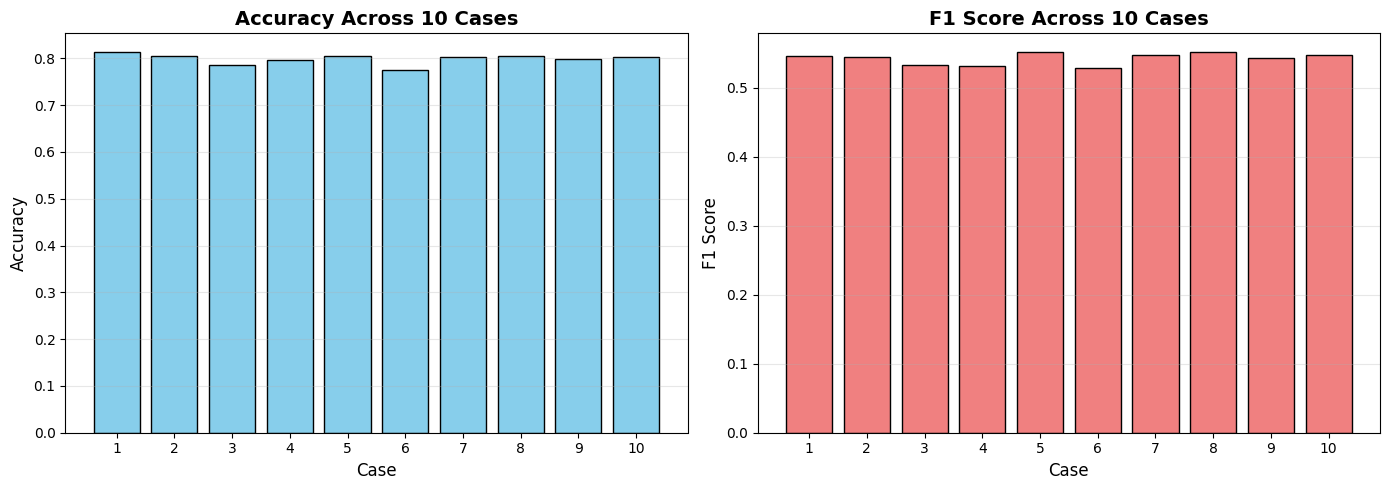


Random Forest Evaluation (Best model obtained from hyperparameter tuning)

Best Hyperparameters:
  n_estimators: 1200
  max_depth: None
  min_samples_split: 15
  min_samples_leaf: 6
  max_features: sqrt

Optimal Threshold: 0.35

Accuracy: 0.8061

Classification Report:
              precision    recall  f1-score   support

           0     0.9439    0.8178    0.8764       247
           1     0.4375    0.7447    0.5512        47

    accuracy                         0.8061       294
   macro avg     0.6907    0.7812    0.7138       294
weighted avg     0.8630    0.8061    0.8244       294



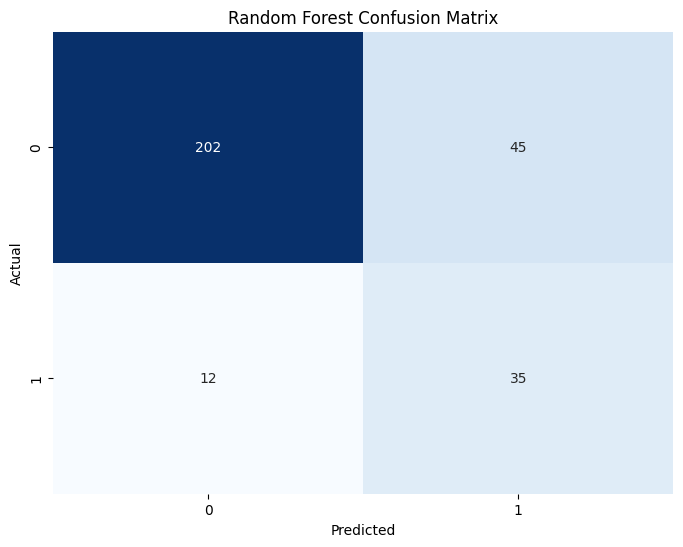

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix

# Trying Model Performance with 10 different sets of hyperparameters (I choose the best 10 so the code doesn't take too long to run)
param_combinations = [
    {'n_estimators': 500, 'max_depth': 10, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt'},
    {'n_estimators': 1000, 'max_depth': 10, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt'},
    {'n_estimators': 1500, 'max_depth': 15, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 'log2'},
    {'n_estimators': 800, 'max_depth': 20, 'min_samples_split': 8, 'min_samples_leaf': 3, 'max_features': 'sqrt'},
    {'n_estimators': 1200, 'max_depth': None, 'min_samples_split': 15, 'min_samples_leaf': 6, 'max_features': 'sqrt'},
    {'n_estimators': 400, 'max_depth': 25, 'min_samples_split': 12, 'min_samples_leaf': 4, 'max_features': 'log2'},
    {'n_estimators': 1000, 'max_depth': 30, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt'},
    {'n_estimators': 1500, 'max_depth': 20, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt'},
    {'n_estimators': 700, 'max_depth': 15, 'min_samples_split': 20, 'min_samples_leaf': 8, 'max_features': 'log2'},
    {'n_estimators': 1000, 'max_depth': None, 'min_samples_split': 10, 'min_samples_leaf': 10, 'max_features': 'sqrt'}
]

# Store results
results = []

for i, params in enumerate(param_combinations, 1):
    print(f"\nCase {i}/10 - Training with parameters: {params}")
    
    # Create and train model
    rf_model = RandomForestClassifier(
        n_estimators=params['n_estimators'],
        max_depth=params['max_depth'],
        min_samples_split=params['min_samples_split'],
        min_samples_leaf=params['min_samples_leaf'],
        max_features=params['max_features'],
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    
    rf_model.fit(X_train_balanced, y_train_balanced)
    
    # Predictions
    rf_prob = rf_model.predict_proba(X_test_scaled)[:,1]
    
    # Find optimal threshold
    best_thresh = 0.5
    best_f1 = 0
    for t in np.arange(0.2, 0.7, 0.01):
        y_pred_t = (rf_prob > t).astype(int)
        f1 = f1_score(y_test, y_pred_t)
        if f1 > best_f1:
            best_f1 = f1
            best_thresh = t
    
    rf_pred = (rf_prob > best_thresh).astype(int)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, rf_pred)
    f1 = f1_score(y_test, rf_pred)
    precision = precision_score(y_test, rf_pred)
    recall = recall_score(y_test, rf_pred)
    
    # Store results
    result = {
        'Case': i,
        'n_estimators': params['n_estimators'],
        'max_depth': params['max_depth'] if params['max_depth'] is not None else 'None',
        'min_samples_split': params['min_samples_split'],
        'min_samples_leaf': params['min_samples_leaf'],
        'max_features': params['max_features'],
        'best_threshold': best_thresh,
        'Accuracy': accuracy,
        'F1 Score': f1,
        'Precision': precision,
        'Recall': recall
    }
    results.append(result)
    
    print(f" Accuracy: {accuracy:.4f} | F1 Score: {f1:.4f} | Threshold: {best_thresh:.2f}")

# Create DataFrame
results_df = pd.DataFrame(results)

# Display results
print("")
print("\nSummary of all 10 model hyperparameters and their performance\n")
print(results_df.to_string(index=False))

# Find best model
best_idx = results_df['F1 Score'].idxmax()
best_case = results_df.loc[best_idx]
best_params = param_combinations[best_idx]

print("\n Best Model:")
print(f"Case {int(best_case['Case'])}")
print(f"  n_estimators: {int(best_case['n_estimators'])}")
print(f"  max_depth: {best_case['max_depth']}")
print(f"  min_samples_split: {int(best_case['min_samples_split'])}")
print(f"  min_samples_leaf: {int(best_case['min_samples_leaf'])}")
print(f"  max_features: {best_case['max_features']}")
print(f"  Accuracy: {best_case['Accuracy']:.4f}")
print(f"  F1 Score: {best_case['F1 Score']:.4f}")
print(f"  Precision: {best_case['Precision']:.4f}")
print(f"  Recall: {best_case['Recall']:.4f}")

# Visualize comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
axes[0].bar(results_df['Case'], results_df['Accuracy'], color='skyblue', edgecolor='black')
axes[0].set_xlabel('Case', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Accuracy Across 10 Cases', fontsize=14, fontweight='bold')
axes[0].set_xticks(results_df['Case'])
axes[0].grid(axis='y', alpha=0.3)

# F1 Score comparison
axes[1].bar(results_df['Case'], results_df['F1 Score'], color='lightcoral', edgecolor='black')
axes[1].set_xlabel('Case', fontsize=12)
axes[1].set_ylabel('F1 Score', fontsize=12)
axes[1].set_title('F1 Score Across 10 Cases', fontsize=14, fontweight='bold')
axes[1].set_xticks(results_df['Case'])
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Training the model with the best hyperparameters found
rf_model = RandomForestClassifier(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    min_samples_split=best_params['min_samples_split'],
    min_samples_leaf=best_params['min_samples_leaf'],
    max_features=best_params['max_features'],
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_balanced, y_train_balanced)

rf_prob = rf_model.predict_proba(X_test_scaled)[:,1]

# Optimal threshold
best_rf_thresh = 0.5
best_rf_f1 = 0
for t in np.arange(0.2, 0.7, 0.01):
    y_pred_t = (rf_prob > t).astype(int)
    f1 = f1_score(y_test, y_pred_t)
    if f1 > best_rf_f1:
        best_rf_f1 = f1
        best_rf_thresh = t

rf_pred = (rf_prob > best_rf_thresh).astype(int)

# Evaluation
print("\nRandom Forest Evaluation (Best model obtained from hyperparameter tuning)")
print(f"\nBest Hyperparameters:")
print(f"  n_estimators: {best_params['n_estimators']}")
print(f"  max_depth: {best_params['max_depth']}")
print(f"  min_samples_split: {best_params['min_samples_split']}")
print(f"  min_samples_leaf: {best_params['min_samples_leaf']}")
print(f"  max_features: {best_params['max_features']}")
print(f"\nOptimal Threshold: {best_rf_thresh:.2f}")

# Accuracy
print(f"\nAccuracy: {accuracy_score(y_test, rf_pred):.4f}")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, rf_pred, digits=4))

plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**7. Train XGBoost**


Case 1/10 - Training with parameters: {'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 2, 'gamma': 0.0, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.0, 'reg_lambda': 1.0}
 Accuracy: 0.8095 | F1 Score: 0.4909 | Threshold: 0.20

Case 2/10 - Training with parameters: {'n_estimators': 1000, 'max_depth': 6, 'learning_rate': 0.03, 'min_child_weight': 3, 'gamma': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 1.0}
 Accuracy: 0.8639 | F1 Score: 0.5556 | Threshold: 0.28

Case 3/10 - Training with parameters: {'n_estimators': 800, 'max_depth': 5, 'learning_rate': 0.04, 'min_child_weight': 1, 'gamma': 0.2, 'subsample': 0.7, 'colsample_bytree': 0.7, 'reg_alpha': 0.2, 'reg_lambda': 1.5}
 Accuracy: 0.8265 | F1 Score: 0.5143 | Threshold: 0.23

Case 4/10 - Training with parameters: {'n_estimators': 1200, 'max_depth': 7, 'learning_rate': 0.02, 'min_child_weight': 4, 'gamma': 0.15, 'subsample': 0.85, 'colsample_bytree': 0.85,

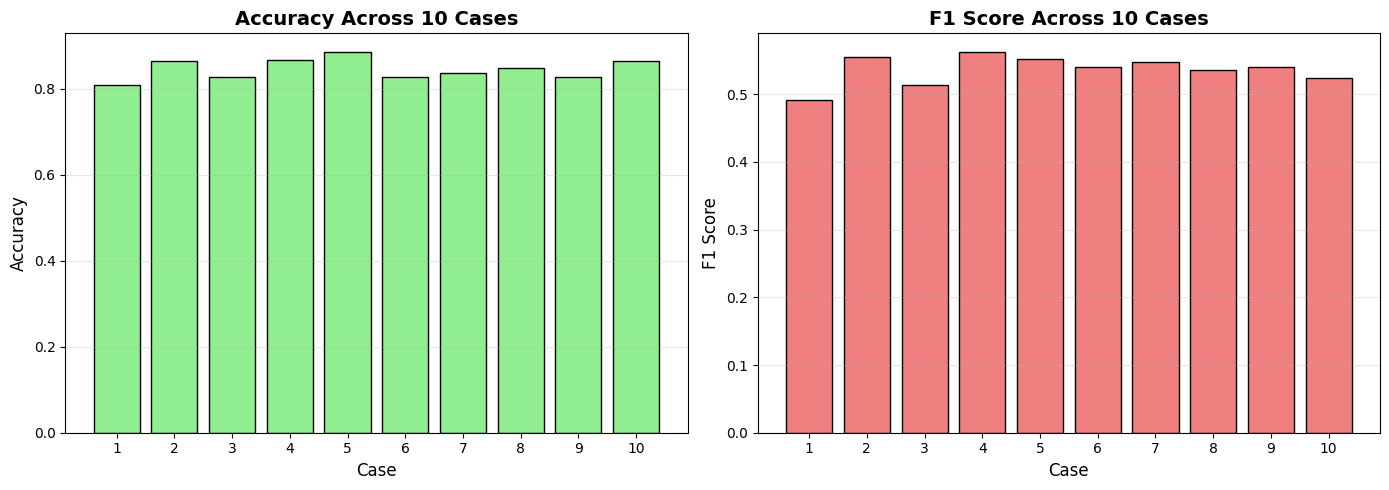


XGBoost Evaluation (Best model obtained from hyperparameter tuning)

Best Hyperparameters:
  n_estimators: 1200
  max_depth: 7
  learning_rate: 0.0200
  min_child_weight: 4
  gamma: 0.15
  subsample: 0.85
  colsample_bytree: 0.85
  reg_alpha: 0.15
  reg_lambda: 1.20

Optimal Threshold: 0.33

Accuracy: 0.8673

Classification Report:
              precision    recall  f1-score   support

           0     0.9127    0.9312    0.9218       247
           1     0.5952    0.5319    0.5618        47

    accuracy                         0.8673       294
   macro avg     0.7540    0.7315    0.7418       294
weighted avg     0.8619    0.8673    0.8643       294



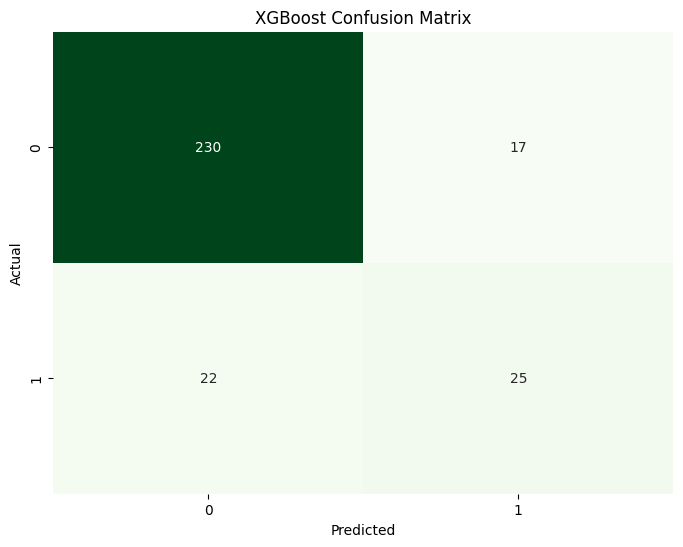

In [8]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Trying Model Performance with 10 different sets of hyperparameters (I choose the best 10 so the code doesn't take too long to run)
param_combinations = [
    {'n_estimators': 500, 'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 2, 'gamma': 0.0, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.0, 'reg_lambda': 1.0},
    {'n_estimators': 1000, 'max_depth': 6, 'learning_rate': 0.03, 'min_child_weight': 3, 'gamma': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 1.0},
    {'n_estimators': 800, 'max_depth': 5, 'learning_rate': 0.04, 'min_child_weight': 1, 'gamma': 0.2, 'subsample': 0.7, 'colsample_bytree': 0.7, 'reg_alpha': 0.2, 'reg_lambda': 1.5},
    {'n_estimators': 1200, 'max_depth': 7, 'learning_rate': 0.02, 'min_child_weight': 4, 'gamma': 0.15, 'subsample': 0.85, 'colsample_bytree': 0.85, 'reg_alpha': 0.15, 'reg_lambda': 1.2},
    {'n_estimators': 600, 'max_depth': 8, 'learning_rate': 0.06, 'min_child_weight': 2, 'gamma': 0.05, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_alpha': 0.05, 'reg_lambda': 0.8},
    {'n_estimators': 800, 'max_depth': 5, 'learning_rate': 0.01, 'min_child_weight': 5, 'gamma': 0.3, 'subsample': 0.75, 'colsample_bytree': 0.75, 'reg_alpha': 0.3, 'reg_lambda': 2.0},
    {'n_estimators': 900, 'max_depth': 6, 'learning_rate': 0.035, 'min_child_weight': 3, 'gamma': 0.1, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 1.0},
    {'n_estimators': 700, 'max_depth': 4, 'learning_rate': 0.07, 'min_child_weight': 1, 'gamma': 0.0, 'subsample': 0.85, 'colsample_bytree': 0.85, 'reg_alpha': 0.0, 'reg_lambda': 1.5},
    {'n_estimators': 900, 'max_depth': 5, 'learning_rate': 0.02, 'min_child_weight': 4, 'gamma': 0.2, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.2, 'reg_lambda': 1.3},
    {'n_estimators': 1100, 'max_depth': 6, 'learning_rate': 0.03, 'min_child_weight': 2, 'gamma': 0.15, 'subsample': 0.9, 'colsample_bytree': 0.9, 'reg_alpha': 0.15, 'reg_lambda': 1.1}
]

# Store results
results = []

for i, params in enumerate(param_combinations, 1):
    print(f"\nCase {i}/10 - Training with parameters: {params}")
    
    # Create and train model
    xgb_model = XGBClassifier(
        n_estimators=params['n_estimators'],
        max_depth=params['max_depth'],
        learning_rate=params['learning_rate'],
        min_child_weight=params['min_child_weight'],
        gamma=params['gamma'],
        subsample=params['subsample'],
        colsample_bytree=params['colsample_bytree'],
        reg_alpha=params['reg_alpha'],
        reg_lambda=params['reg_lambda'],
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    )
    
    X_train_bal, X_val_bal, y_train_bal, y_val_bal = train_test_split(
        X_train_balanced, y_train_balanced, test_size=0.2, random_state=42
    )
    
    xgb_model.fit(X_train_bal, y_train_bal, verbose=False)
    
    # Predictions
    xgb_prob = xgb_model.predict_proba(X_test_scaled)[:,1]
    
    # Find optimal threshold
    best_thresh = 0.5
    best_f1 = 0
    for t in np.arange(0.2, 0.7, 0.01):
        y_pred_t = (xgb_prob > t).astype(int)
        f1 = f1_score(y_test, y_pred_t)
        if f1 > best_f1:
            best_f1 = f1
            best_thresh = t
    
    xgb_pred = (xgb_prob > best_thresh).astype(int)
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, xgb_pred)
    f1 = f1_score(y_test, xgb_pred)
    precision = precision_score(y_test, xgb_pred)
    recall = recall_score(y_test, xgb_pred)
    
    # Store results
    result = {
        'Case': i,
        'n_estimators': params['n_estimators'],
        'max_depth': params['max_depth'],
        'learning_rate': params['learning_rate'],
        'min_child_weight': params['min_child_weight'],
        'gamma': params['gamma'],
        'subsample': params['subsample'],
        'colsample_bytree': params['colsample_bytree'],
        'reg_alpha': params['reg_alpha'],
        'reg_lambda': params['reg_lambda'],
        'best_threshold': best_thresh,
        'Accuracy': accuracy,
        'F1 Score': f1,
    }
    results.append(result)
    
    print(f" Accuracy: {accuracy:.4f} | F1 Score: {f1:.4f} | Threshold: {best_thresh:.2f}")

# Create DataFrame
results_df = pd.DataFrame(results)

# Display results
print("")
print("\nSummary of all 10 model hyperparameters and their performance\n")
print(results_df.to_string(index=False))

# Find best model
best_idx = results_df['F1 Score'].idxmax()
best_case = results_df.loc[best_idx]
best_params = param_combinations[best_idx]

print("\n Best Model:")
print(f"Case {int(best_case['Case'])}")
print(f"  n_estimators: {int(best_case['n_estimators'])}")
print(f"  max_depth: {int(best_case['max_depth'])}")
print(f"  learning_rate: {best_case['learning_rate']:.4f}")
print(f"  min_child_weight: {int(best_case['min_child_weight'])}")
print(f"  gamma: {best_case['gamma']:.2f}")
print(f"  subsample: {best_case['subsample']:.2f}")
print(f"  colsample_bytree: {best_case['colsample_bytree']:.2f}")
print(f"  reg_alpha: {best_case['reg_alpha']:.2f}")
print(f"  reg_lambda: {best_case['reg_lambda']:.2f}")
print(f"  Accuracy: {best_case['Accuracy']:.4f}")
print(f"  F1 Score: {best_case['F1 Score']:.4f}")

# Visualize comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy comparison
axes[0].bar(results_df['Case'], results_df['Accuracy'], color='lightgreen', edgecolor='black')
axes[0].set_xlabel('Case', fontsize=12)
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Accuracy Across 10 Cases', fontsize=14, fontweight='bold')
axes[0].set_xticks(results_df['Case'])
axes[0].grid(axis='y', alpha=0.3)

# F1 Score comparison
axes[1].bar(results_df['Case'], results_df['F1 Score'], color='lightcoral', edgecolor='black')
axes[1].set_xlabel('Case', fontsize=12)
axes[1].set_ylabel('F1 Score', fontsize=12)
axes[1].set_title('F1 Score Across 10 Cases', fontsize=14, fontweight='bold')
axes[1].set_xticks(results_df['Case'])
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Training the model with the best hyperparameters found
xgb_model = XGBClassifier(
    n_estimators=best_params['n_estimators'],
    max_depth=best_params['max_depth'],
    learning_rate=best_params['learning_rate'],
    min_child_weight=best_params['min_child_weight'],
    gamma=best_params['gamma'],
    subsample=best_params['subsample'],
    colsample_bytree=best_params['colsample_bytree'],
    reg_alpha=best_params['reg_alpha'],
    reg_lambda=best_params['reg_lambda'],
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

X_train_bal, X_val_bal, y_train_bal, y_val_bal = train_test_split(
    X_train_balanced, y_train_balanced, test_size=0.2, random_state=42
)

xgb_model.fit(X_train_bal, y_train_bal, verbose=False)

xgb_prob = xgb_model.predict_proba(X_test_scaled)[:,1]

# Optimal threshold
best_xgb_thresh = 0.5
best_xgb_f1 = 0
for t in np.arange(0.2, 0.7, 0.01):
    y_pred_t = (xgb_prob > t).astype(int)
    f1 = f1_score(y_test, y_pred_t)
    if f1 > best_xgb_f1:
        best_xgb_f1 = f1
        best_xgb_thresh = t

xgb_pred = (xgb_prob > best_xgb_thresh).astype(int)

# Evaluation
print("\nXGBoost Evaluation (Best model obtained from hyperparameter tuning)")
print(f"\nBest Hyperparameters:")
print(f"  n_estimators: {best_params['n_estimators']}")
print(f"  max_depth: {best_params['max_depth']}")
print(f"  learning_rate: {best_params['learning_rate']:.4f}")
print(f"  min_child_weight: {best_params['min_child_weight']}")
print(f"  gamma: {best_params['gamma']:.2f}")
print(f"  subsample: {best_params['subsample']:.2f}")
print(f"  colsample_bytree: {best_params['colsample_bytree']:.2f}")
print(f"  reg_alpha: {best_params['reg_alpha']:.2f}")
print(f"  reg_lambda: {best_params['reg_lambda']:.2f}")
print(f"\nOptimal Threshold: {best_xgb_thresh:.2f}")

# Accuracy
print(f"\nAccuracy: {accuracy_score(y_test, xgb_pred):.4f}")

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, xgb_pred, digits=4))

plt.figure(figsize=(8,6))
sns.heatmap(confusion_matrix(y_test, xgb_pred), annot=True, fmt='d', cmap='Greens', cbar=False)
plt.title("XGBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**8. Feature Importance**


Top 15 Most Important Features:
                Feature  RF_Importance  XGB_Importance  Avg_Importance
               JobLevel       0.065441        0.118922        0.092181
       StockOptionLevel       0.069718        0.092629        0.081173
             Department       0.029996        0.058260        0.044128
          MaritalStatus       0.051557        0.033843        0.042700
               OverTime       0.024909        0.047451        0.036180
        JobSatisfaction       0.033309        0.038967        0.036138
      Work_Life_Balance       0.036110        0.033408        0.034759
   YearsWithCurrManager       0.037486        0.025701        0.031594
EnvironmentSatisfaction       0.033081        0.029112        0.031097
         BusinessTravel       0.016063        0.045585        0.030824
         JobInvolvement       0.024257        0.036378        0.030317
  OverTime_Satisfaction       0.027842        0.032474        0.030158
                    Age       0.039648      

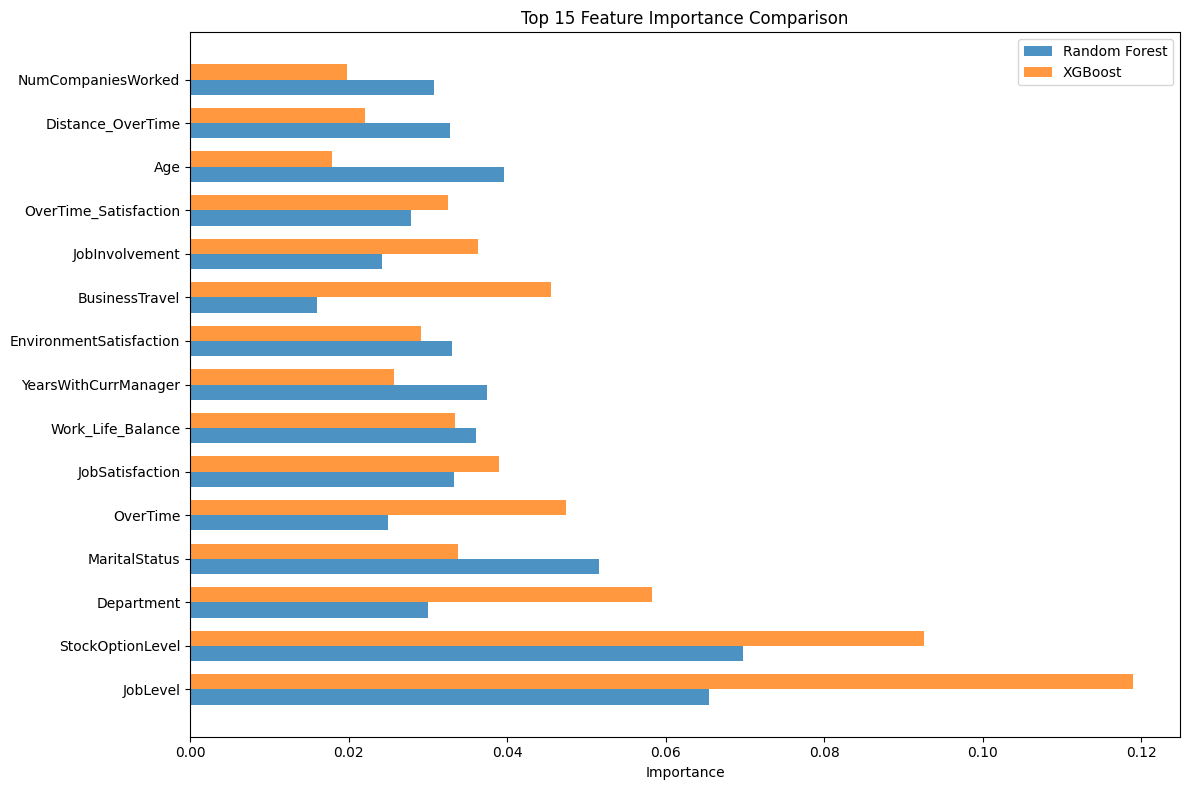

In [9]:
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'RF_Importance': rf_model.feature_importances_,
    'XGB_Importance': xgb_model.feature_importances_
})
feature_importance['Avg_Importance'] = (feature_importance['RF_Importance'] + feature_importance['XGB_Importance']) / 2
feature_importance = feature_importance.sort_values('Avg_Importance', ascending=False)

print("\nTop 15 Most Important Features:")
print(feature_importance.head(15).to_string(index=False))

plt.figure(figsize=(12,8))
top_features = feature_importance.head(15)
x = np.arange(len(top_features))
width = 0.35
plt.barh(x - width/2, top_features['RF_Importance'], width, label='Random Forest', alpha=0.8)
plt.barh(x + width/2, top_features['XGB_Importance'], width, label='XGBoost', alpha=0.8)
plt.yticks(x, top_features['Feature'])
plt.xlabel('Importance')
plt.title('Top 15 Feature Importance Comparison')
plt.legend()
plt.tight_layout()
plt.show()

**9. Compare Models and Choose Best**

In [10]:
rf_score = f1_score(y_test, rf_pred)
xgb_score = f1_score(y_test, xgb_pred)
best_model = "Random Forest" if rf_score > xgb_score else "XGBoost"

print("\nFinal Model Comparison and Choosing the Best Model")
print(f"Random Forest F1: {rf_score:.4f}")
print(f"XGBoost F1: {xgb_score:.4f}")
print(f"\nBest Model: {best_model} (F1 Score: {max(rf_score, xgb_score):.4f})")


Final Model Comparison and Choosing the Best Model
Random Forest F1: 0.5512
XGBoost F1: 0.5618

Best Model: XGBoost (F1 Score: 0.5618)


**10. Business-Focused Thresholds**

In [11]:
print("Business-Focused Threshhold Analysis for Best Model (XGBoost)")
print("")

# High Recall (catch most attrition, accept more false alarms)
high_recall_thresh = 0.10
xgb_high_recall = (xgb_prob > high_recall_thresh).astype(int)

# Balanced (default threshold from training)
balanced_thresh = best_xgb_thresh
xgb_balanced = xgb_pred

# High Precision (fewer false alarms, may miss some attrition)
high_precision_thresh = 0.60
xgb_high_precision = (xgb_prob > high_precision_thresh).astype(int)

print(f"{'Strategy':<20} {'Threshold':<12} {'Precision':<12} {'Recall':<12} {'F1':<12}")
print("-" * 68)
print(f"{'High Recall':<20} {high_recall_thresh:<12.2f} "
      f"{precision_score(y_test, xgb_high_recall):<12.4f} "
      f"{recall_score(y_test, xgb_high_recall):<12.4f} "
      f"{f1_score(y_test, xgb_high_recall):<12.4f}")
print(f"{'Balanced':<20} {balanced_thresh:<12.2f} "
      f"{precision_score(y_test, xgb_balanced):<12.4f} "
      f"{recall_score(y_test, xgb_balanced):<12.4f} "
      f"{f1_score(y_test, xgb_balanced):<12.4f}")
print(f"{'High Precision':<20} {high_precision_thresh:<12.2f} "
      f"{precision_score(y_test, xgb_high_precision):<12.4f} "
      f"{recall_score(y_test, xgb_high_precision):<12.4f} "
      f"{f1_score(y_test, xgb_high_precision):<12.4f}")

print("")
print("- Use 'High Recall' if retention is critical")
print("- Use 'Balanced' for general use")
print("- Use 'High Precision' if intervention resources are limited")

Business-Focused Threshhold Analysis for Best Model (XGBoost)

Strategy             Threshold    Precision    Recall       F1          
--------------------------------------------------------------------
High Recall          0.10         0.3535       0.7447       0.4795      
Balanced             0.33         0.5952       0.5319       0.5618      
High Precision       0.60         0.7143       0.3191       0.4412      

- Use 'High Recall' if retention is critical
- Use 'Balanced' for general use
- Use 'High Precision' if intervention resources are limited


**11. Saving Models**

In [12]:
import pickle
import os

# Create model directory
os.makedirs('../model', exist_ok=True)

# 1. Scaler
with open('../model/scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)

# 2. Label Encoders
with open('../model/label_encoders.pkl', 'wb') as f:
    pickle.dump(label_encoders, f)

# 3. Feature order (after all preprocessing & feature engineering)
with open('../model/feature_order.pkl', 'wb') as f:
    pickle.dump(X.columns.tolist(), f)

# 4. Trained models
with open('../model/final_rf_model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

with open('../model/final_xgb_model.pkl', 'wb') as f:
    pickle.dump(xgb_model, f)

# 5. Optimal thresholds
thresholds = {
    'rf_optimal': best_rf_thresh,
    'xgb_optimal': best_xgb_thresh
}
with open('../model/optimal_thresholds.pkl', 'wb') as f:
    pickle.dump(thresholds, f)


# 6. Model Performance
rf_accuracy = accuracy_score(y_test, rf_pred)
xgb_accuracy = accuracy_score(y_test, xgb_pred)

test_data = {
    'y_test': y_test,
    'rf_predictions': rf_pred,
    'xgb_predictions': xgb_pred,
    'rf_proba': rf_prob,
    'xgb_proba': xgb_prob,
    'rf_accuracy': rf_accuracy,
    'xgb_accuracy': xgb_accuracy
}

with open('../model/test_predictions.pkl', 'wb') as f:
    pickle.dump(test_data, f)

**12. Finding Dissagreements between Best Models with Random Forest and XGBoost with optimum threshhold**

In [13]:
disagreement_idx = np.where((rf_prob > 0.33) & (xgb_prob < 0.33) | (rf_prob < 0.33) & (xgb_prob > 0.33))[0] 
print(f"Found {len(disagreement_idx)} strong disagreements") 
print("\nExample cases where RF says 'stay' but XGB says 'leave':") 
for idx in disagreement_idx[:100]: 
    actual = y_test.iloc[idx] 
    print(f"\n--- Case {idx} ---") 
    print(f"Actual: {'LEFT' if actual == 1 else 'STAYED'}") 
    print(f"RF Probability: {rf_prob[idx]:.3f}") 
    print(f"XGB Probability: {xgb_prob[idx]:.3f}")
    employee_data = X_test.iloc[idx] 
    print(employee_data.to_string())
rf_correct = (rf_pred[disagreement_idx] == y_test.iloc[disagreement_idx]).sum() 
xgb_correct = (xgb_pred[disagreement_idx] == y_test.iloc[disagreement_idx]).sum() 
print(f"\nWhen models strongly disagree:") 
print(f"Random Forest correct: {rf_correct}/{len(disagreement_idx)}") 
print(f"XGBoost correct: {xgb_correct}/{len(disagreement_idx)}")

Found 55 strong disagreements

Example cases where RF says 'stay' but XGB says 'leave':

--- Case 5 ---
Actual: STAYED
RF Probability: 0.364
XGB Probability: 0.071
Age                            40.000000
BusinessTravel                  2.000000
DailyRate                     448.000000
Department                      1.000000
DistanceFromHome               16.000000
Education                       3.000000
EducationField                  1.000000
EmployeeCount                   1.000000
EmployeeNumber               1641.000000
EnvironmentSatisfaction         3.000000
Gender                          0.000000
HourlyRate                     84.000000
JobInvolvement                  3.000000
JobLevel                        3.000000
JobRole                         4.000000
JobSatisfaction                 4.000000
MaritalStatus                   2.000000
MonthlyIncome                7945.000000
MonthlyRate                 19948.000000
NumCompaniesWorked              6.000000
Over18          